# TP Chaînes de Markov - Master M2 IMB

In [36]:
import numpy as np
import matplotlib.pyplot as plt
from numpy.random import choice as choice

## Exercice 1

### Question 1

In [37]:
# On fait d'abord quelques essais "au brouillon", pour préparer la réponse à la question:

# On crée un vecteur de taille n=10 qui contiendra les valeurs de x1, x2, ... simulées.
n = 10
x = np.zeros(n, dtype=int)
print(x)

[0 0 0 0 0 0 0 0 0 0]


In [38]:
# On initialise x[0]=1 (= valeur de x1):
x[0] = 1
# puis on simule x[1] (= valeur de x2), en tirant au sort suivant la loi conditionnelle P(X2=1|X1=1)=0.37, P(X2=2|X1=1)=0.63:
x[1] = choice([1,2],p=[0.37,0.63])
print(x[1])

2


In [39]:
# puis on simule x[2] (= valeur de x3), en tirant au sort suivant la loi conditionnelle, 
# qui dépend de la valeur de x[1]:
if x[1]==1:
    x[2] = choice([1,2],p=[0.37,0.63])
else:
    x[2] = choice([1,2],p=[0.42,0.58])
print(x[2])

2


In [40]:
# A présent on peut répondre à la question: on définit une fonction qui renvoie le vecteur x contenant les valeurs
# simulées de la chaîne de Markov (N.B on n'est pas obligé d'écrire une fonction, on pourrati aussi écrire le code directement):

def simul_markov(n,x1):
    x = np.zeros(n, dtype=int)
    x[0] = x1
    for i in range(n-1):
        if x[i]==1:
            x[i+1] = choice([1,2],p=[0.37,0.63])
        else:
            x[i+1] = choice([1,2],p=[0.42,0.58])
    return x

# On teste la fonction:
x = simul_markov(10,1)
print(x)

[1 1 2 1 2 1 1 2 1 1]


In [41]:
# Si on teste plusieurs fois, on obtient des simulations différentes:
x=simul_markov(10,1); print(x)
x=simul_markov(10,1); print(x)
x=simul_markov(10,1); print(x)
x=simul_markov(10,1); print(x)

[1 2 2 1 1 1 1 2 1 2]
[1 1 1 2 2 1 1 2 2 2]
[1 1 1 2 2 1 1 2 2 1]
[1 2 2 1 2 1 2 2 2 2]


In [42]:
# Test en partant de l'état 2 au lieu de l'état 1:
x=simul_markov(10,2)
print(x)

[2 2 2 1 1 2 2 1 2 1]


In [43]:
# Test pour n=100
x=simul_markov(100,1)
print(x)

[1 2 2 2 2 2 2 1 2 1 2 1 2 1 2 2 2 2 2 1 1 2 1 2 2 2 2 1 2 2 1 1 1 2 2 1 1
 1 1 1 2 1 1 2 2 2 1 1 2 1 1 2 2 2 1 2 2 1 1 2 1 1 2 1 2 2 2 2 1 1 1 1 1 2
 1 2 2 1 1 2 1 2 1 2 2 1 1 2 1 2 1 2 2 1 2 2 2 1 1 2]


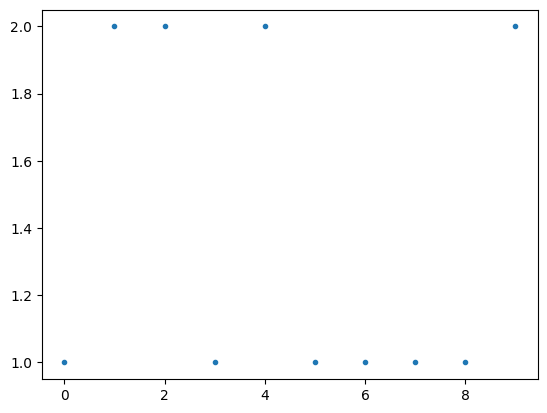

In [44]:
# affichage graphique:
x = simul_markov(10,1)
plt.plot(x,'.');

### Question 3

In [45]:
# On pourrait recopier le code de la question 1 en modifiant les valeurs des probabilités,
# mais on va en profiter pour faire une fonction plus générique qui prend en entrée la 
# matrice de transition:

def simul_markov(T,n,x1):
    # T est la matrice de transition
    x = np.zeros(n, dtype=int)
    x[0] = x1
    for i in range(n-1):
        # on considère les deux cas x[i]==1 ou x[i]==2
        # (N.B. donc ce code ne peut fonctionner que pour une chaîne à deux états 1 et 2)
        if x[i]==1:
            x[i+1] = choice([1,2],p=T[0])
        else:
            x[i+1] = choice([1,2],p=T[1])
    return x

T2 = np.array([[0.7,0.3],[0.2,0.8]])
x = simul_markov(T2,10,1)
print(x)

[1 2 2 1 2 2 1 1 2 1]


In [46]:
# autre version plus compacte, en évitant le if...else. Cette version
# fonctionne pour n'importe quel nombre d'états:
# (N.B. ce n'était pas vrai car j'avais écrit choice([1,2],...)
# J'ai corrigé pendant la séance du 2 novembre.

def simul_markov(T,n,x1):
    # T est la matrice de transition
    x = np.zeros(n, dtype=int)
    x[0] = x1
    ne = T.shape[0]  # nombre d'états
    for i in range(n-1):
        x[i+1] = choice(range(1,ne+1),p=T[x[i]-1])
        # N.B. on a écrit T[x[i]-1] au lieu de T[x[i]] car les indices en Python partent de 0,
        # alors que les états sont numérotés à partir de 1. On pourrait simplifier le code
        # en décidant de numéroter les états à partir de 0, ainsi que partir de n=0 au lieu de n=1.
    return x

x = simul_markov(T2,10,1)
print(x)

[1 1 2 2 2 2 2 2 1 1]


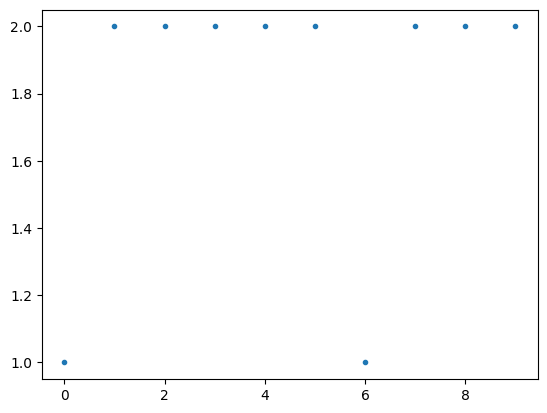

In [47]:
x = simul_markov(T2,10,1)
plt.plot(x,'.');

In [48]:
# bonus : on peut regarder la convergence des pi(n) vers la loi stationnaire:

# vecteur ligne pi(1) = (P(X1=1),P(X1=2)) = (1,0)
pi1 = np.array([[1,0]])
pi2 = pi1 @ T2
print(pi2)

[[0.7 0.3]]


In [49]:
pi3 = pi2 @ T2
print(pi3)

[[0.55 0.45]]


In [50]:
# on calcule pi(n) pour n=100. Du fait de la convergence très rapide vers
# la loi stationnaire, ce vecteur est en fait numériquement égal à la loi limite:
pi_101 = pi1 @ np.linalg.matrix_power(T2,99)
print(pi_101)

[[0.4 0.6]]


### Question 4

In [60]:
T3 = np.array([[0.85,0.15],[0.10,0.90]])
x = simul_markov(T3,10,1)
print(x)

[1 1 1 2 1 2 2 2 2 2]


In [61]:
pi1 = np.array([[1,0]])
pi_101 = pi1 @ np.linalg.matrix_power(T3,99)
print(pi_101)

[[0.4 0.6]]


In [62]:
print(pi1 @ np.linalg.matrix_power(T3,5))

[[0.54238281 0.45761719]]


In [55]:
for k in range(50):
    print(pi1 @ np.linalg.matrix_power(T3,k))

[[1. 0.]]
[[0.85 0.15]]
[[0.7375 0.2625]]
[[0.653125 0.346875]]
[[0.58984375 0.41015625]]
[[0.54238281 0.45761719]]
[[0.50678711 0.49321289]]
[[0.48009033 0.51990967]]
[[0.46006775 0.53993225]]
[[0.44505081 0.55494919]]
[[0.43378811 0.56621189]]
[[0.42534108 0.57465892]]
[[0.41900581 0.58099419]]
[[0.41425436 0.58574564]]
[[0.41069077 0.58930923]]
[[0.40801808 0.59198192]]
[[0.40601356 0.59398644]]
[[0.40451017 0.59548983]]
[[0.40338263 0.59661737]]
[[0.40253697 0.59746303]]
[[0.40190273 0.59809727]]
[[0.40142705 0.59857295]]
[[0.40107028 0.59892972]]
[[0.40080271 0.59919729]]
[[0.40060203 0.59939797]]
[[0.40045153 0.59954847]]
[[0.40033864 0.59966136]]
[[0.40025398 0.59974602]]
[[0.40019049 0.59980951]]
[[0.40014287 0.59985713]]
[[0.40010715 0.59989285]]
[[0.40008036 0.59991964]]
[[0.40006027 0.59993973]]
[[0.4000452 0.5999548]]
[[0.4000339 0.5999661]]
[[0.40002543 0.59997457]]
[[0.40001907 0.59998093]]
[[0.4000143 0.5999857]]
[[0.40001073 0.59998927]]
[[0.40000805 0.59999195]]
[[0.40

In [56]:
# vérification de la vitesse de convergence:
# on peut calculer e(n) = ||mu_n-mu|| pour chaque n:
n = 100
e = np.zeros(n)
mu = np.array([[0.4,0.6]])
for k in range(n):
    mu_k = pi1 @ np.linalg.matrix_power(T3,k)
    e[k] = np.linalg.norm(mu_k-mu)
print(e)

[8.48528137e-01 6.36396103e-01 4.77297077e-01 3.57972808e-01
 2.68479606e-01 2.01359704e-01 1.51019778e-01 1.13264834e-01
 8.49486253e-02 6.37114690e-02 4.77836017e-02 3.58377013e-02
 2.68782760e-02 2.01587070e-02 1.51190302e-02 1.13392727e-02
 8.50445451e-03 6.37834088e-03 4.78375566e-03 3.58781675e-03
 2.69086256e-03 2.01814692e-03 1.51361019e-03 1.13520764e-03
 8.51405732e-04 6.38554299e-04 4.78915724e-04 3.59186793e-04
 2.69390095e-04 2.02042571e-04 1.51531928e-04 1.13648946e-04
 8.52367097e-05 6.39275323e-05 4.79456492e-05 3.59592369e-05
 2.69694277e-05 2.02270708e-05 1.51703031e-05 1.13777273e-05
 8.53329548e-06 6.39997161e-06 4.79997871e-06 3.59998403e-06
 2.69998802e-06 2.02499102e-06 1.51874326e-06 1.13905745e-06
 8.54293085e-07 6.40719814e-07 4.80539860e-07 3.60404895e-07
 2.70303671e-07 2.02727753e-07 1.52045815e-07 1.14034361e-07
 8.55257709e-08 6.41443281e-08 4.81082461e-08 3.60811845e-08
 2.70608883e-08 2.02956662e-08 1.52217496e-08 1.14163122e-08
 8.56223407e-09 6.421675

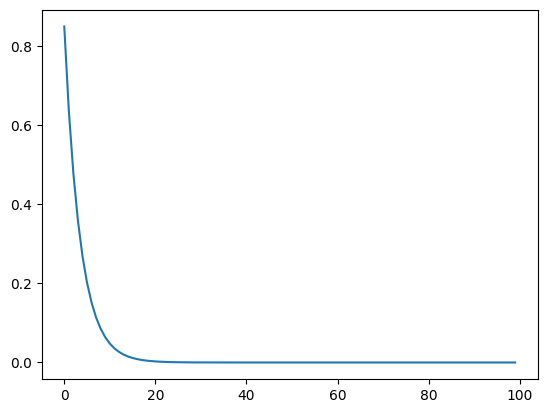

In [57]:
plt.plot(e);

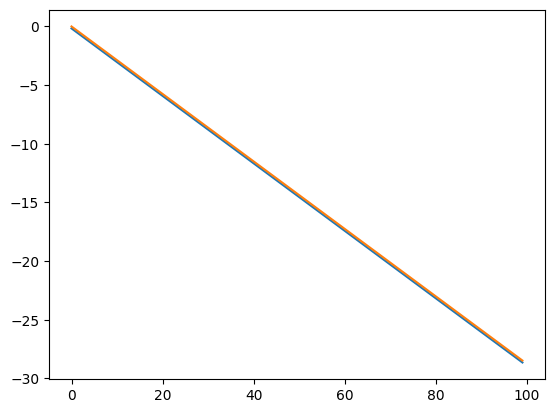

In [58]:
# on peut afficher un graphique en échelle logarithmique
plt.plot(np.log(e))
# on affoche aussi une doite de pente log(0.75) pour voir si on a la même pente que log(e):
k = np.arange(100)
plt.plot(k,np.log(0.75)*k);
# on observe bien que les deux droites sont parallèles

## Exercice 3

### Question 5

In [59]:
T = np.array([[0.1,0.8,0,0,0.1],[0.8,0,0.2,0,0],[0,0,0.6,0.4,0],[0,0,0.8,0.2,0],[0,0,0,0,1]])
print(T)

[[0.1 0.8 0.  0.  0.1]
 [0.8 0.  0.2 0.  0. ]
 [0.  0.  0.6 0.4 0. ]
 [0.  0.  0.8 0.2 0. ]
 [0.  0.  0.  0.  1. ]]


In [29]:
simul_markov(T,10,1)

array([1, 5, 5, 5, 5, 5, 5, 5, 5, 5])

In [30]:
simul_markov(T,10,1)

array([1, 2, 3, 3, 3, 3, 3, 3, 3, 3])

In [31]:
simul_markov(T,10,1)

array([1, 2, 1, 2, 1, 2, 1, 2, 1, 5])

In [35]:
simul_markov(T,100,1)

array([1, 2, 1, 2, 1, 2, 1, 2, 1, 1, 2, 3, 4, 4, 3, 3, 3, 3, 3, 3, 3, 4,
       3, 4, 3, 3, 3, 3, 4, 3, 3, 3, 4, 3, 4, 3, 3, 4, 3, 4, 3, 4, 3, 3,
       3, 3, 3, 4, 3, 3, 3, 3, 4, 3, 3, 3, 3, 4, 3, 3, 4, 3, 3, 3, 3, 3,
       3, 3, 3, 3, 3, 3, 4, 4, 3, 3, 4, 3, 4, 4, 3, 4, 3, 4, 3, 4, 3, 3,
       4, 3, 3, 4, 3, 4, 4, 3, 3, 3, 3, 3])